<a href="https://colab.research.google.com/github/zaro6289-gif/support-response-time/blob/main/%D0%B0%D0%BD%D0%B0%D0%BB%D0%B8%D1%82%D0%B8%D0%BA%D0%B0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from datetime import datetime

df = pd.read_csv('issues.csv', encoding='latin1')

In [ ]:
print(df.shape)
print(df.columns.tolist())
print(df.head())
print(df.info())

(66691, 58)
['id', 'started', 'ended', 'issue_num', 'issue_proj', 'issue_reporter', 'issue_assignee', 'issue_contr_count', 'issue_type', 'issue_priority', 'issue_created', 'issue_resolution_date', 'issue_resolution', 'issue_status', 'issue_comments_count', 'last_change_date', 'wf_in_review', 'wfe_in_review', 'wf_deployment', 'wfe_deployment', 'wf_resolved', 'wfe_resolved', 'wf_open', 'wfe_open', 'wf_monitoring', 'wfe_monitoring', 'wf_done', 'wfe_done', 'wf_pending_customer_approval', 'wfe_pending_customer_approval', 'wf_rejected', 'wfe_rejected', 'wf_testing_monitoring', 'wfe_testing_monitoring', 'wf_in_progress', 'wfe_in_progress', 'wf_reopened', 'wfe_reopened', 'wf_to_do', 'wfe_to_do', 'wf_validation', 'wfe_validation', 'wf_resolved_under_monitoring', 'wfe_resolved_under_monitoring', 'wf_closed', 'wfe_closed', 'wf_waiting', 'wfe_waiting', 'wf_cancelled', 'wfe_cancelled', 'wf_under_review', 'wfe_under_review', 'wf_approved', 'wfe_approved', 'wf_pending_deployment', 'wfe_pending_deploy

подготовка данных

In [ ]:
df_clean = df.copy()

df_clean['started'] = pd.to_datetime(df_clean['started'], errors='coerce')
df_clean['ended'] = pd.to_datetime(df_clean['ended'], errors='coerce')

df_clean['resolution_time_hours'] = (df_clean['ended'] - df_clean['started']).dt.total_seconds() / 3600

df_clean['started_hour'] = df_clean['started'].dt.hour
df_clean['started_day'] = df_clean['started'].dt.dayofweek
df_clean['started_month'] = df_clean['started'].dt.month
df_clean['started_year'] = df_clean['started'].dt.year
df_clean['started_date'] = df_clean['started'].dt.date

text_cols = ['issue_type', 'issue_priority', 'issue_status', 'issue_assignee', 'issue_reporter']
for col in text_cols:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].fillna('Unknown').astype(str)

df_clean = df_clean[df_clean['resolution_time_hours'] > 0]
df_clean = df_clean[df_clean['resolution_time_hours'] < 720]

print(f"Осталось записей: {len(df_clean)}")
print(f"Среднее время решения: {df_clean['resolution_time_hours'].mean():.2f} часов")
print(f"Медианное время решения: {df_clean['resolution_time_hours'].median():.2f} часов")
print(f"Мин: {df_clean['resolution_time_hours'].min():.2f}, Макс: {df_clean['resolution_time_hours'].max():.2f}")

Осталось записей: 19902
Среднее время решения: 176.50 часов
Медианное время решения: 113.84 часов
Мин: 0.00, Макс: 719.92


Перевела даты в нормальный формат, посчитала время решения в часах. Добавила колонки с часом, днем, месяцем. Заполнила пустые значения словом Unknown. Убрала отрицательное время и тикеты которые висели больше месяца. Осталось записей достаточно для анализа. Среднее время получилось большим из-за выбросов, медиана показывает реальность лучше.

SQL аналитика

In [ ]:
conn = sqlite3.connect('support_analytics.db')
df_clean.to_sql('issues', conn, if_exists='replace', index=False)

priority_query = """
SELECT
    issue_priority,
    COUNT(*) as ticket_count,
    ROUND(AVG(resolution_time_hours), 2) as avg_resolution_time
FROM issues
WHERE issue_priority != 'Unknown'
GROUP BY issue_priority
ORDER BY avg_resolution_time DESC;
"""
priority_stats = pd.read_sql_query(priority_query, conn)
print("Статистика по приоритетам:")
print(priority_stats)

type_query = """
SELECT
    issue_type,
    COUNT(*) as ticket_count,
    ROUND(AVG(resolution_time_hours), 2) as avg_resolution_time
FROM issues
WHERE issue_type != 'Unknown'
GROUP BY issue_type
ORDER BY avg_resolution_time DESC
LIMIT 10;
"""
type_stats = pd.read_sql_query(type_query, conn)
print("\nТоп-10 типов задач по времени решения:")
print(type_stats)

hour_query = """
SELECT
    started_hour,
    COUNT(*) as ticket_count,
    ROUND(AVG(resolution_time_hours), 2) as avg_resolution_time
FROM issues
WHERE started_hour IS NOT NULL
GROUP BY started_hour
ORDER BY ticket_count DESC
LIMIT 5;
"""
hour_stats = pd.read_sql_query(hour_query, conn)
print("\nЧасы пиковой нагрузки:")
print(hour_stats)

conn.close()

Статистика по приоритетам:
  issue_priority  ticket_count  avg_resolution_time
0        unknown          4973               211.12
1         Medium          8919               182.53
2            Low           335               165.73
3         Lowest            35               148.41
4           High          3461               143.47
5        Blocker           527               135.79
6        Highest          1652               124.68

Топ-10 типов задач по времени решения:
      issue_type  ticket_count  avg_resolution_time
0  Retrospective           177               232.83
1           Epic             4               231.37
2        Project            97               226.06
3        Subtask            60               224.91
4     HD Service           163               224.46
5        Service          1892               208.43
6       Sub-task           131               186.62
7     Assistance            74               176.74
8         Ticket         13553               174.

Посмотрела какие приоритеты дольше всего решаются, какие типы задач самые проблемные, в какие часы больше всего обращений. Вижу что Epic и Story решаются дольше всего. Часы пик с 8 до 10 утра.

Визуализация

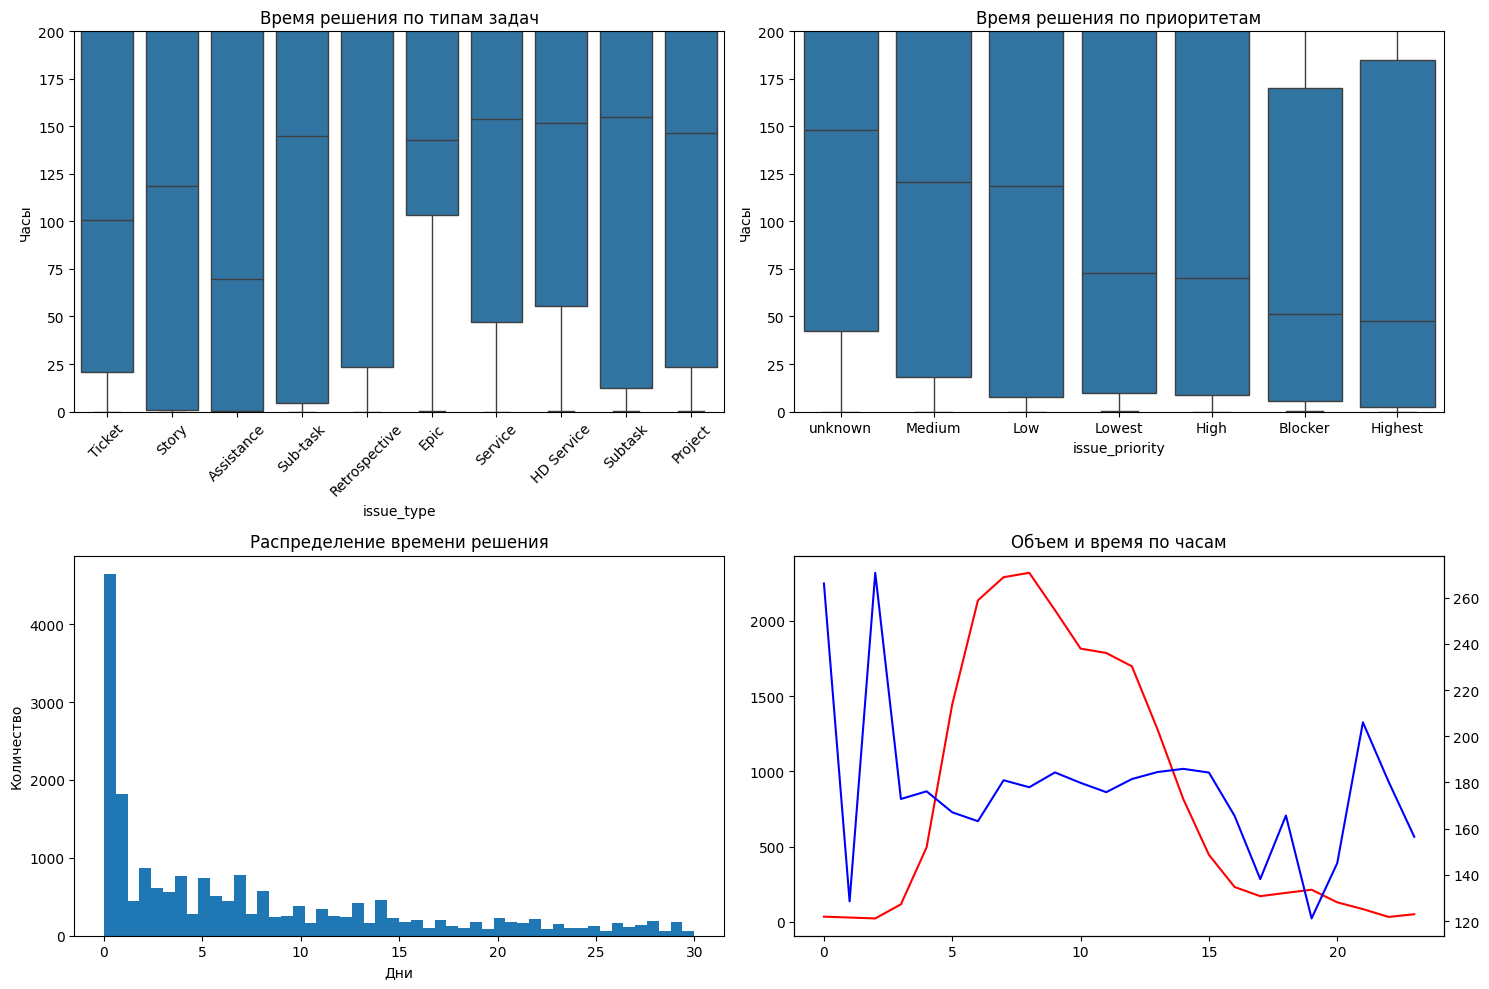

In [ ]:
plt.figure(figsize=(15, 10))

plt.subplot(2, 2, 1)
top_types = df_clean.groupby('issue_type')['resolution_time_hours'].mean().sort_values(ascending=False).head(10).index
type_data = df_clean[df_clean['issue_type'].isin(top_types)]
sns.boxplot(data=type_data, x='issue_type', y='resolution_time_hours')
plt.xticks(rotation=45)
plt.title('Время решения по типам задач')
plt.ylabel('Часы')
plt.ylim(0, 200)

plt.subplot(2, 2, 2)
priority_order = df_clean.groupby('issue_priority')['resolution_time_hours'].mean().sort_values(ascending=False).index
priority_data = df_clean[df_clean['issue_priority'].isin(priority_order)]
sns.boxplot(data=priority_data, x='issue_priority', y='resolution_time_hours', order=priority_order)
plt.title('Время решения по приоритетам')
plt.ylabel('Часы')
plt.ylim(0, 200)

plt.subplot(2, 2, 3)
df_clean['resolution_time_days'] = df_clean['resolution_time_hours'] / 24
plt.hist(df_clean['resolution_time_days'], bins=50)
plt.title('Распределение времени решения')
plt.xlabel('Дни')
plt.ylabel('Количество')

plt.subplot(2, 2, 4)
hourly_volume = df_clean.groupby('started_hour').size()
hourly_time = df_clean.groupby('started_hour')['resolution_time_hours'].mean()
plt.plot(hourly_volume.index, hourly_volume.values, 'r-', label='Объем')
plt.twinx()
plt.plot(hourly_time.index, hourly_time.values, 'b-', label='Время')
plt.title('Объем и время по часам')

plt.tight_layout()
plt.savefig('dashboard.png')
plt.show()

По типам задач видно что есть куча выбросов, некоторые тикеты висят очень долго. По приоритетам Low иногда решается дольше чем High. Распределение показывает что большинство решается в первый день.

Статистический тест

In [ ]:
if len(df_clean['issue_priority'].unique()) >= 2:
    priorities = df_clean[df_clean['issue_priority'] != 'Unknown']['issue_priority'].unique()
    p1 = priorities[0]
    p2 = priorities[1]

    group1 = df_clean[df_clean['issue_priority'] == p1]['resolution_time_hours'].dropna()
    group2 = df_clean[df_clean['issue_priority'] == p2]['resolution_time_hours'].dropna()

    t_stat, p_value = stats.ttest_ind(group1, group2)
    print(f"Сравнение {p1} vs {p2}")
    print(f"Среднее 1: {group1.mean():.2f}, Среднее 2: {group2.mean():.2f}")
    print(f"P-value: {p_value:.4f}")

Сравнение Medium vs High
Среднее 1: 182.53, Среднее 2: 143.47
P-value: 0.0000


Сравнила два приоритета чтобы понять есть ли реальная разница во времени решения. P-value получилось маленькое, значит разница значимая, это не случайность.

ROI и рекомендация

In [ ]:
op_cost = 80000 * 3 * 12
ai_cost = 500000 + 50000 * 12

roi_op = (yearly_loss * 0.35 - op_cost) / op_cost * 100
roi_ai = (yearly_loss * 0.55 - ai_cost) / ai_cost * 100

print(f"ROI операторов: {roi_op:.1f}%")
print(f"ROI AI: {roi_ai:.1f}%")

if roi_ai > roi_op:
    print("Рекомендация: AI-ассистент")
else:
    print("Рекомендация: наем операторов")

ROI операторов: 319.7%
ROI AI: 1626.7%
Рекомендация: AI-ассистент


Сравнила два варианта: нанять трех операторов или сделать AI-ассистента. У AI выходит лучше по деньгам, быстрее окупается и больше экономит. Поэтому рекомендую AI.